# Classification of Coral-Reef Benthic Point Annotations
## Moorea Labeled Corals (MLC) 2010 CNN vs DNN
Ahmed Zakwaan Shareef (TP078882)

## Setup & Configuration

In [1]:
import os
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent   # this notebook lives in <project>/notebooks
os.makedirs(PROJECT_ROOT / "cache", exist_ok=True)
os.makedirs(PROJECT_ROOT / "models", exist_ok=True)
os.makedirs(PROJECT_ROOT / "figures", exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: /mnt/c/dev/APU/ODL


In [2]:
import re, glob, json, time, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt

plt.rcParams["figure.dpi"]   = 110
plt.rcParams["savefig.bbox"] = "tight"
plt.style.use("default")

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1789732711.137499  103557 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789732718.745543  103557 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789732724.999613  103557 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#### Configuration

In [3]:
class CFG:
    # --- Paths 
    DATA_DIR  = str(PROJECT_ROOT / "Moorea Labeled Corals 2010")

    CACHE_DIR = str(PROJECT_ROOT / "cache")
    MODEL_DIR = str(PROJECT_ROOT / "models")
    FIG_DIR   = str(PROJECT_ROOT / "figures")

    # Random seed value
    SEED = 42

    # --- Patch extraction 
    # square window cut from the source image, centred on the annotated point cropped wider for context
    CROP_PX    = 112
    # the patch is resized to this before the model sees it  
    INPUT_SIZE = 64

    # --- Class mapping
    # 27 labels mapped onto 6 functional groups for classification
    CLASS_MAP = {
        "CCA": "CCA",
        "Sand": "Sand",
        "Turf": "Turf",
        "Macro": "Macroalgae", "Lobo": "Macroalgae",
        "Off": "Other", "Soft": "Other",
        "Porit": "Hard coral", "P.Rus": "Hard coral", "P.Irr": "Hard coral", "Pmass": "Hard coral",
        "Pocill": "Hard coral", "Monti": "Hard coral", "Pavon": "Hard coral", "Mille": "Hard coral",
        "Acrop": "Hard coral", "Monta": "Hard coral", "Lepta": "Hard coral", "Fung": "Hard coral",
        "Gardin": "Hard coral", "Herpo": "Hard coral", "Favia": "Hard coral", "Cypha": "Hard coral",
        "Acan": "Hard coral", "Astreo": "Hard coral", "Psam": "Hard coral", "Lepto": "Hard coral",
    }
    CLASSES = ["CCA", "Hard coral", "Sand", "Turf", "Macroalgae", "Other"]

    # --- Class balancing (training split only)
    # undersample dominant class
    CCA_CAP = 12_000    

    # --- Splitting by image (fractions of dataset)
    TEST_FRAC = 0.15
    VAL_FRAC  = 0.15  

    # --- Training 
    BATCH_SIZE = 128
    EPOCHS     = 40
    LR         = 1e-3

    # --- Tuning 
    TUNE_TRIALS = 6
    TUNE_EPOCHS = 15

for _d in (CFG.CACHE_DIR, CFG.MODEL_DIR, CFG.FIG_DIR):
    os.makedirs(_d, exist_ok=True)

N_CLASSES    = len(CFG.CLASSES)
LABEL_TO_IDX = {c: i for i, c in enumerate(CFG.CLASSES)}
IDX_TO_LABEL = {i: c for c, i in LABEL_TO_IDX.items()}

#### Set seed

In [6]:
def set_seed(seed=CFG.SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed()

In [7]:
class BalancedAccuracy(keras.metrics.Metric):
    # Macro averaged per class recall
    def __init__(self, num_classes, name="balanced_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.confusion = self.add_weight(name="confusion",
                                         shape=(num_classes, num_classes),
                                         initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.cast(tf.argmax(y_pred, axis=-1), tf.int32)
        cm = tf.math.confusion_matrix(y_true, y_pred,
                                      num_classes=self.num_classes, dtype=tf.float32)
        self.confusion.assign_add(cm)

    def result(self):
        correct = tf.linalg.diag_part(self.confusion)
        totals  = tf.reduce_sum(self.confusion, axis=1)
        recalls = tf.math.divide_no_nan(correct, totals)
        present = tf.cast(totals > 0, tf.float32)
        return tf.math.divide_no_nan(tf.reduce_sum(recalls), tf.reduce_sum(present))

    def reset_state(self):
        self.confusion.assign(tf.zeros((self.num_classes, self.num_classes)))


## Data Loading & Parsing

In [8]:
assert os.path.isdir(CFG.DATA_DIR), f"DATA_DIR not found: {CFG.DATA_DIR}"
print(len(glob.glob(os.path.join(CFG.DATA_DIR, "*.jpg"))), "images found")

629 images found


#### Construct df

In [10]:
def parse_annotations(data_dir):
    # Read every *.jpg.txt in *data_dir* into one DataFrame
    # Each file has a header line # Row; Col; Label then 
    # ~200 lines of row; col; label. Row = pixel y, Col = pixel x
    records = []
    txt_files = sorted(glob.glob(os.path.join(data_dir, "*.jpg.txt")))
    assert txt_files, f"no *.jpg.txt in {data_dir}"
    for txt in txt_files:
        img_path = txt[:-4]                          # drop ".txt" -> "<name>.jpg"
        if not os.path.exists(img_path):
            print("WARNING: no image for", os.path.basename(txt)); continue
        with open(txt) as fh:
            for line in fh:
                line = line.strip()
                if not line or line.startswith("#"):
                    continue
                parts = [p.strip() for p in line.split(";")]
                if len(parts) != 3:
                    continue
                r, c, label = parts
                records.append((os.path.basename(img_path), img_path, int(r), int(c), label))
    return pd.DataFrame(records, columns=["image", "img_path", "row", "col", "label_raw"])

df = parse_annotations(CFG.DATA_DIR)
n_img = df.image.nunique()
print(f"{n_img} images | {len(df):,} annotated points | {len(df)/n_img:.0f} points/image")
df.head()

629 images | 125,171 annotated points | 199 points/image


,image,img_path,row,col,label_raw
0,mcr_lter1_fringingreef_pole1-2_qu1_20100411.jpg,/mnt/c/dev/APU/ODL/Moorea Labeled Corals 2010/...,1440,1364,CCA
1,mcr_lter1_fringingreef_pole1-2_qu1_20100411.jpg,/mnt/c/dev/APU/ODL/Moorea Labeled Corals 2010/...,773,1505,CCA
2,mcr_lter1_fringingreef_pole1-2_qu1_20100411.jpg,/mnt/c/dev/APU/ODL/Moorea Labeled Corals 2010/...,1130,438,CCA
3,mcr_lter1_fringingreef_pole1-2_qu1_20100411.jpg,/mnt/c/dev/APU/ODL/Moorea Labeled Corals 2010/...,997,343,Sand
4,mcr_lter1_fringingreef_pole1-2_qu1_20100411.jpg,/mnt/c/dev/APU/ODL/Moorea Labeled Corals 2010/...,938,1324,Sand


#### Integrity Checks

In [11]:
print("Missing values per column: \n", df.isnull().sum().to_string(), "\n")
print("Points per image: \n", df.groupby("image").size().describe().to_string(), "\n")

dims = {p: cv2.imread(p).shape[:2] for p in df.img_path.unique()}      # {path: (h, w)}
dim_df = pd.DataFrame(dims.values(), columns=["h", "w"])
print(f"Image height {dim_df.h.min()}-{dim_df.h.max()} px, "
      f"width {dim_df.w.min()}-{dim_df.w.max()} px")

df["h"] = df.img_path.map(lambda p: dims[p][0])
df["w"] = df.img_path.map(lambda p: dims[p][1])
oob = ((df.row < 0) | (df.col < 0) | (df.row >= df.h) | (df.col >= df.w)).sum()
print(f"Points on/over the border: {oob} ({100*oob/len(df):.2f}%) "
      f"-> handled by reflect-padding at extraction time")

Missing values per column: 
 image        0
img_path     0
row          0
col          0
label_raw    0 

Points per image: 
 count    629.0
mean     199.0
std        0.0
min      199.0
25%      199.0
50%      199.0
75%      199.0
max      199.0 

Image height 1708-2000 px, width 1664-1980 px
Points on/over the border: 0 (0.00%) -> handled by reflect-padding at extraction time


## Exploratory Data Analysis

#### Raw label distribution

label_raw
CCA       84854
Sand      11185
Off        6201
P. Rus     6097
Turf       4751
Porit      3481
Macro      2979
Monti      2106
Pavon      1575
Pocill      807
P mass      314
Mille       262
Acrop       178
Monta        91
Soft         76
Lepta        56
P. Irr       48
Lobo         39
Fung         22
Gardin       18
Favia         7
Herpo         7
Cypha         6
Acan          5
Astreo        4
Psam          1
Lepto         1


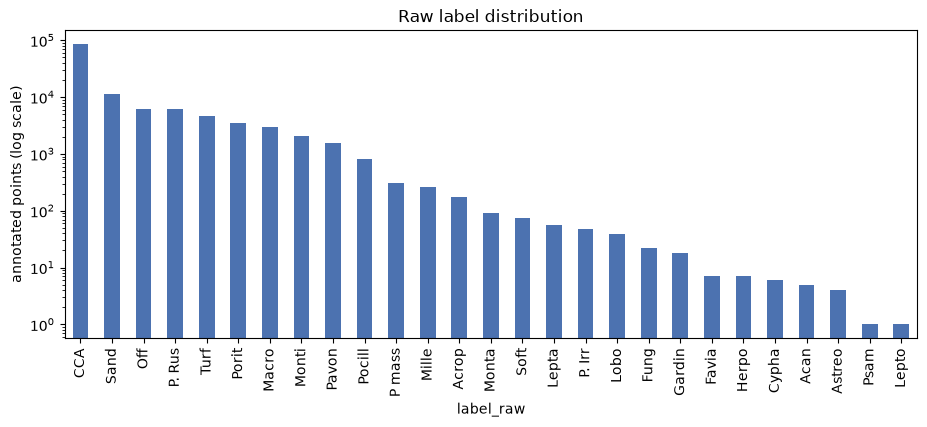

In [9]:
raw_counts = df.label_raw.value_counts()
print(raw_counts.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
raw_counts.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_yscale("log")
ax.set_ylabel("annotated points (log scale)")
ax.set_title(f"Raw label distribution")
plt.savefig(f"{CFG.FIG_DIR}/eda_raw_class_distribution.png"); plt.show()

#### Quadrat photo point scatter

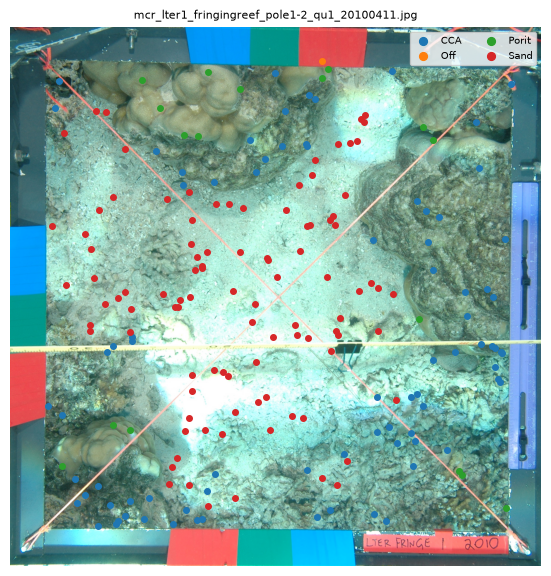

In [10]:
def show_image_with_points(image_name, ax=None):
    """Full quadrat photo with its annotation points, coloured by raw label."""
    sub = df[df.image == image_name]
    img = cv2.cvtColor(cv2.imread(sub.img_path.iloc[0]), cv2.COLOR_BGR2RGB)
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(img)
    for lab, g in sub.groupby("label_raw"):
        ax.scatter(g.col, g.row, s=16, label=lab)
    ax.legend(fontsize=7, markerscale=1.4, ncol=2, loc="upper right")
    ax.set_title(image_name, fontsize=8); ax.axis("off")

show_image_with_points(sorted(df.image.unique())[0])
plt.savefig(f"{CFG.FIG_DIR}/eda_points_overlay.png"); plt.show()

#### Image brightness histogram

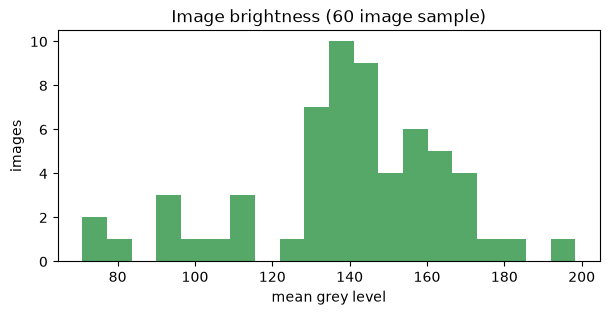

In [11]:
sample_paths = (df.img_path.drop_duplicates()
                  .sample(min(60, df.image.nunique()), random_state=CFG.SEED))
brightness = [cv2.imread(p, cv2.IMREAD_GRAYSCALE).mean() for p in sample_paths]
plt.figure(figsize=(7, 3))
plt.hist(brightness, bins=20, color="#55A868")
plt.xlabel("mean grey level"); plt.ylabel("images")
plt.title("Image brightness (60 image sample)")
plt.savefig(f"{CFG.FIG_DIR}/eda_brightness.png"); plt.show()

## Preprocessing

#### Class mapping

In [12]:
# A few files spell some labels with spaces ("P. Rus", "P mass", "P. Irr") so needs to be normalized before mapping
df["label_key"] = df.label_raw.str.replace(" ", "", regex=False)
df["label"]     = df.label_key.map(CFG.CLASS_MAP)

unmapped = sorted(df.loc[df.label.isna(), "label_key"].unique())
if unmapped:
    n_drop = int(df.label.isna().sum())
    print(f"Dropping {n_drop} points with labels not in CLASS_MAP: {unmapped}")
    df = df.dropna(subset=["label"]).reset_index(drop=True)

grouped_counts = df.label.value_counts().reindex(CFG.CLASSES)
print(grouped_counts.to_string())

label
CCA           84854
Hard coral    15086
Sand          11185
Turf           4751
Macroalgae     3018
Other          6277


Plot unmapped to grouped counts distribution

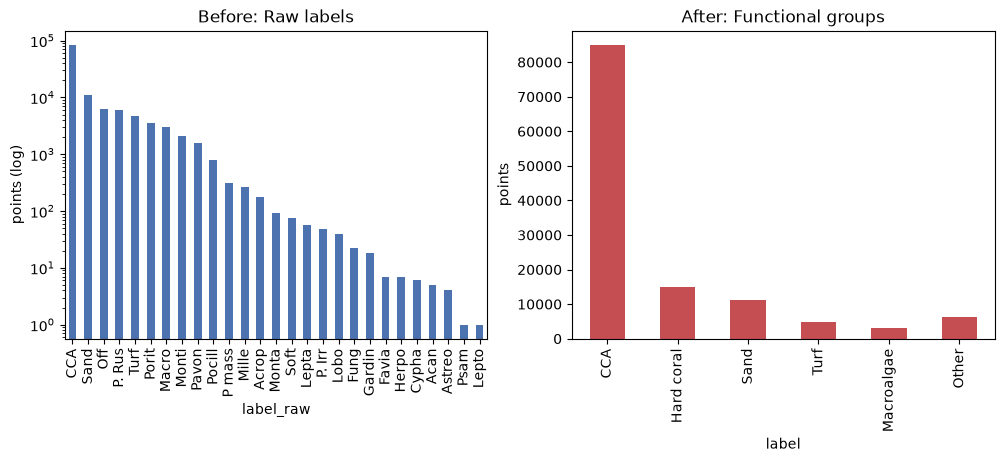

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.label_raw.value_counts().plot(kind="bar", ax=axes[0], color="#4C72B0", logy=True)
axes[0].set_title("Before: Raw labels"); axes[0].set_ylabel("points (log)")
grouped_counts.plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("After: Functional groups"); axes[1].set_ylabel("points")
plt.savefig(f"{CFG.FIG_DIR}/prep_class_grouping.png"); plt.show()

#### Patch extraction

Crop window centred on (r, c). Resize to (out x out) pixels

In [13]:
def extract_patch(img, r, c, crop=None, out=None):
    crop = crop or CFG.CROP_PX
    out  = out  or CFG.INPUT_SIZE
    half = crop // 2
    r = int(np.clip(r, 0, img.shape[0] - 1))   # clamp (few points sit just outside the image)
    c = int(np.clip(c, 0, img.shape[1] - 1))
    padded = cv2.copyMakeBorder(img, half, half, half, half, cv2.BORDER_REFLECT_101)
    rr, cc = r + half, c + half
    patch  = padded[rr - half: rr + half, cc - half: cc + half]
    return cv2.resize(patch, (out, out), interpolation=cv2.INTER_AREA)

Extract every patch per frame

In [14]:
def build_patch_arrays(frame, cache_tag):
    xp = os.path.join(CFG.CACHE_DIR, f"X_{cache_tag}.npy")
    yp = os.path.join(CFG.CACHE_DIR, f"y_{cache_tag}.npy")
    gp = os.path.join(CFG.CACHE_DIR, f"groups_{cache_tag}.npy")
    if all(os.path.exists(p) for p in (xp, yp, gp)):
        print("Loading cached patches:", cache_tag)
        return np.load(xp), np.load(yp), np.load(gp, allow_pickle=True)

    n = len(frame)
    X = np.empty((n, CFG.INPUT_SIZE, CFG.INPUT_SIZE, 3), dtype=np.uint8)
    y = np.empty(n, dtype=np.int64)
    g = np.empty(n, dtype=object)
    pos, t0 = 0, time.time()
    for k, (img_path, sub) in enumerate(frame.groupby("img_path", sort=False), 1):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        for _, rr in sub.iterrows():
            X[pos] = extract_patch(img, rr.row, rr.col)
            y[pos] = LABEL_TO_IDX[rr.label]
            g[pos] = rr.image
            pos += 1
        if k % 100 == 0:
            print(f"  {k} images, {pos:,}/{n:,} patches ({time.time()-t0:.0f}s)")
    assert pos == n
    np.save(xp, X); np.save(yp, y); np.save(gp, g)
    print(f"Extracted {n:,} patches in {time.time()-t0:.0f}s -> {xp}")
    return X, y, g

Sort by img_path and reset the index so DataFrame row k == array row k

In [15]:
df = df.sort_values("img_path").reset_index(drop=True)
CACHE_TAG = f"crop{CFG.CROP_PX}_in{CFG.INPUT_SIZE}_clean"
X_all, y_all, groups_all = build_patch_arrays(df, CACHE_TAG)
print("X_all:", X_all.shape, X_all.dtype, f"({X_all.nbytes/1e9:.2f} GB in RAM)")

Loading cached patches: crop112_in64_clean
X_all: (125171, 64, 64, 3) uint8 (1.54 GB in RAM)


Plot sample patches per class

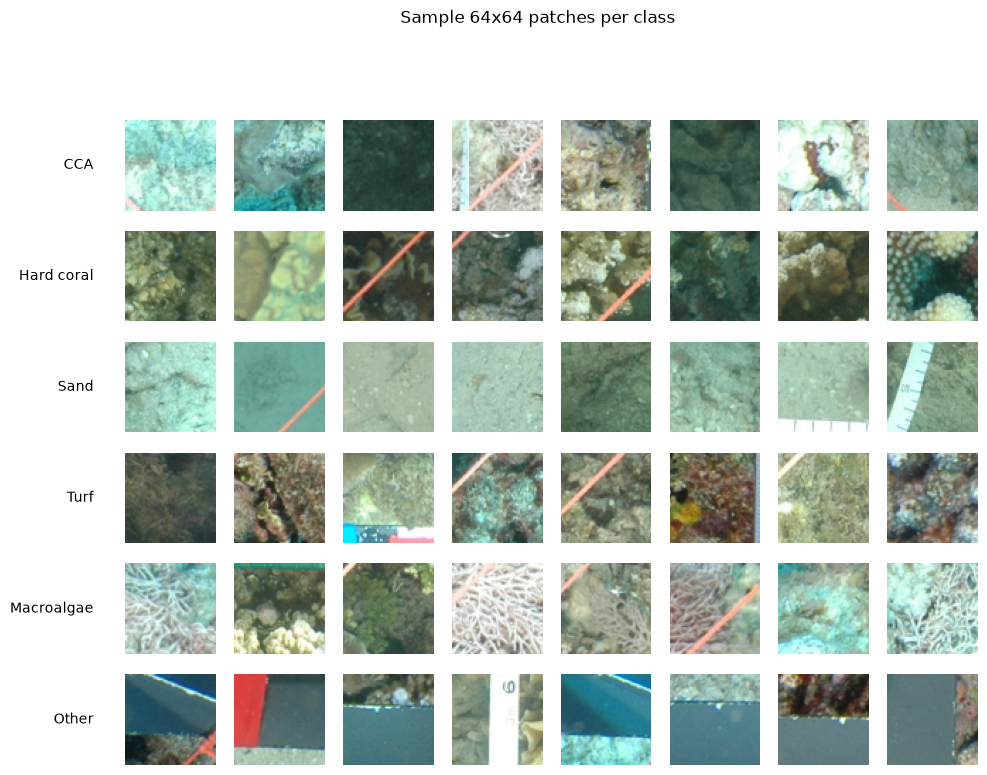

In [17]:
set_seed()
fig, axes = plt.subplots(N_CLASSES, 8, figsize=(11, 1.4 * N_CLASSES))
for i, cls in enumerate(CFG.CLASSES):
    pool = np.where(y_all == LABEL_TO_IDX[cls])[0]
    for j, k in enumerate(np.random.choice(pool, 8, replace=False)):
        axes[i, j].imshow(X_all[k]); axes[i, j].axis("off")
    axes[i, 0].text(-0.35, 0.5, cls, transform=axes[i, 0].transAxes,
                    ha="right", va="center", fontsize=10)
plt.suptitle(f"Sample {CFG.INPUT_SIZE}x{CFG.INPUT_SIZE} patches per class", y=1.01)
plt.savefig(f"{CFG.FIG_DIR}/prep_sample_patches.png"); plt.show()

#### Train / validation / test splitting

In [16]:
# GroupShuffleSplit only needs shape + groups
_dummy = np.zeros(len(df)) 

gss1 = GroupShuffleSplit(n_splits=1, test_size=CFG.TEST_FRAC, random_state=CFG.SEED)
trainval_idx, test_idx = next(gss1.split(_dummy, y_all, groups_all))

# val fraction within the trainval part
val_rel = CFG.VAL_FRAC / (1 - CFG.TEST_FRAC)     
gss2 = GroupShuffleSplit(n_splits=1, test_size=val_rel, random_state=CFG.SEED)
tr_rel, val_rel_idx = next(gss2.split(_dummy[trainval_idx],
                                     y_all[trainval_idx], groups_all[trainval_idx]))
train_idx = trainval_idx[tr_rel]
val_idx   = trainval_idx[val_rel_idx]

# no image should appear in more than one split
assert not (set(groups_all[train_idx]) & set(groups_all[test_idx]))
assert not (set(groups_all[val_idx])   & set(groups_all[test_idx]))
assert not (set(groups_all[train_idx]) & set(groups_all[val_idx]))

for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s}  {len(idx):>7,} patches  {len(set(groups_all[idx])):>3} images")

train   87,361 patches  439 images
val     18,905 patches   95 images
test    18,905 patches   95 images


Undersample CCA, then oversample the smallest classes within TRAINING split (val/test stay at their natural distribution)

In [17]:
rng   = np.random.default_rng(CFG.SEED)
cca_i = LABEL_TO_IDX["CCA"]
tr_cca  = train_idx[y_all[train_idx] == cca_i]
tr_rest = train_idx[y_all[train_idx] != cca_i]
if len(tr_cca) > CFG.CCA_CAP:
    tr_cca = rng.choice(tr_cca, CFG.CCA_CAP, replace=False)
train_idx_bal = np.concatenate([tr_cca, tr_rest])

counts = pd.Series(y_all[train_idx_bal]).value_counts()
target = int(counts.drop(cca_i).median())
for cls in ("Turf", "Macroalgae"):
    ci   = LABEL_TO_IDX[cls]
    pool = train_idx_bal[y_all[train_idx_bal] == ci]
    if len(pool) < target:
        extra = rng.choice(pool, target - len(pool), replace=True)
        train_idx_bal = np.concatenate([train_idx_bal, extra])

rng.shuffle(train_idx_bal)

class_weight = {i: w for i, w in enumerate(
    compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_all[train_idx_bal]))}
print("class_weight:", {CFG.CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

class_weight: {'CCA': np.float64(0.61), 'Hard coral': np.float64(0.67), 'Sand': np.float64(0.92), 'Turf': np.float64(1.67), 'Macroalgae': np.float64(1.67), 'Other': np.float64(1.67)}


Plot train before and after balancing

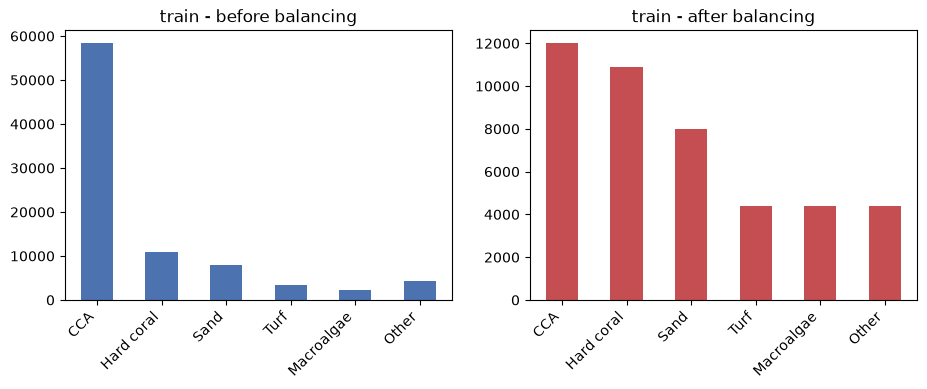

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, idx, title, colour in [
        (axes[0], train_idx,     "train - before balancing", "#4C72B0"),
        (axes[1], train_idx_bal, "train - after balancing",  "#C44E52")]:
    counts_plot = pd.Series(y_all[idx]).value_counts().reindex(range(N_CLASSES)).fillna(0)
    counts_plot.plot(kind="bar", ax=ax, color=colour)
    ax.set_title(title); ax.set_xticklabels(CFG.CLASSES, rotation=45, ha="right")
plt.savefig(f"{CFG.FIG_DIR}/prep_balance.png"); plt.show()

#### Augmentation

In [18]:
AUTOTUNE = tf.data.AUTOTUNE

Fresh augmentation stack (new layer objects each call, so it can go in several models)

In [19]:
def make_augment():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.15),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
        layers.RandomContrast(0.15),
    ], name="augment")

In [20]:
def make_ds(idx, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (X_all[idx], y_all[idx].astype("int32")))
    if training:
        ds = ds.shuffle(min(len(idx), 20_000), seed=CFG.SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.batch(CFG.BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_idx_bal, training=True)
val_ds   = make_ds(val_idx,       training=False)
test_ds  = make_ds(test_idx,      training=False)

I0000 00:00:1789733293.060383  103557 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3620 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Plot an augmented batch preview

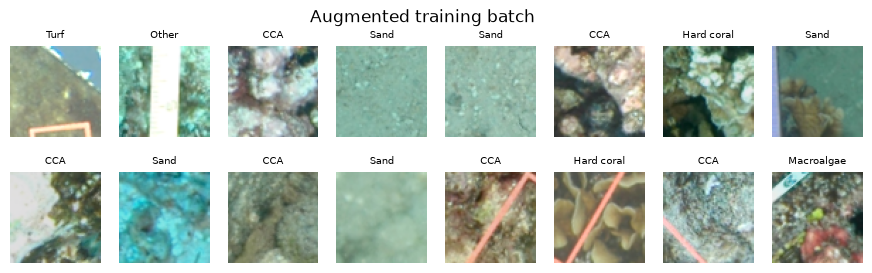

In [24]:
_aug = make_augment()
_xb, _yb = next(iter(train_ds))
_xb_aug = _aug(_xb, training=True)
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for ax, im, lab in zip(axes.ravel(), _xb_aug, _yb):
    ax.imshow(tf.cast(tf.clip_by_value(im, 0, 255), tf.uint8)); ax.axis("off")
    ax.set_title(CFG.CLASSES[int(lab)], fontsize=7)
plt.suptitle("Augmented training batch"); plt.savefig(f"{CFG.FIG_DIR}/prep_augmented.png"); plt.show()

In [22]:
np.savez(os.path.join(CFG.CACHE_DIR, "splits.npz"),
         train=train_idx_bal, val=val_idx, test=test_idx,
         class_weight=np.array([class_weight[i] for i in range(N_CLASSES)]))
print("saved ->", os.path.join(CFG.CACHE_DIR, "splits.npz"))

saved -> /mnt/c/dev/APU/ODL/cache/splits.npz


## Shared Training & Evaluation Utilities

#### Train Model Function

In [23]:
def train_model(model, tag, train_ds, val_ds, epochs=CFG.EPOCHS, class_weight=None):
    ckpt = os.path.join(CFG.MODEL_DIR, f"{tag}.keras")
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_balanced_accuracy", mode="max", patience=8,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=4, min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_balanced_accuracy", mode="max", save_best_only=True),
    ]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=class_weight, callbacks=callbacks, verbose=2)
    dt = time.time() - t0
    print(f"\n{tag}: {dt:.0f}s | best val_accuracy = {max(hist.history['val_accuracy']):.4f} "
          f"| best val_balanced_accuracy = {max(hist.history['val_balanced_accuracy']):.4f}")
    with open(os.path.join(CFG.MODEL_DIR, f"{tag}_history.json"), "w") as fh:
        json.dump(hist.history, fh)
    return hist

#### Plot validation curves function

In [24]:
def plot_curves(hist, tag):
    h = hist.history if hasattr(hist, "history") else hist
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
    ax[0].set_title(f"{tag} - accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
    ax[1].set_title(f"{tag} - loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.savefig(f"{CFG.FIG_DIR}/{tag}_learning_curves.png"); plt.show()

#### Test set accuracy + macro-F1 output function

In [25]:
def quick_eval(model, tag, test_ds):
    """Test-set accuracy + macro-F1"""
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = model.predict(test_ds, verbose=0).argmax(1)
    acc, mf1 = (y_true == y_pred).mean(), f1_score(y_true, y_pred, average="macro")
    print(f"{tag}: test accuracy = {acc:.4f} | macro-F1 = {mf1:.4f}")
    return y_true, y_pred

## Convolutional Neural Network (CNN)

#### Build

In [26]:
def build_cnn(input_size=CFG.INPUT_SIZE, n_classes=N_CLASSES, lr=CFG.LR):
    model = keras.Sequential([
        keras.Input((input_size, input_size, 3)),
        make_augment(),
        layers.Rescaling(1.0 / 255),

        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(128, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(128, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.30),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.50),
        layers.Dense(n_classes, activation="softmax"),
    ], name="cnn_from_scratch")

    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", BalancedAccuracy(n_classes)])
    return model

cnn = build_cnn()
cnn.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augment (Sequential)            │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,338,278 (5.11 MB)

 Trainable params: 1,337,382 (5.10 MB)

 Non-trainable params: 896 (3.50 KB)

#### Train

In [27]:
set_seed()
cnn_hist = train_model(cnn, "cnn", train_ds, val_ds, class_weight=class_weight)

Epoch 1/40


/home/zechn/miniconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1789733548.228377  103557 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/cnn_from_scratch_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1789733556.264284  104453 cuda_dnn.cc:461] Loaded cuDNN version 92600


345/345 - 120s - 347ms/step - accuracy: 0.3472 - balanced_accuracy: 0.3716 - loss: 1.5512 - val_accuracy: 0.2447 - val_balanced_accuracy: 0.3890 - val_loss: 1.5482 - learning_rate: 0.0010
Epoch 2/40
345/345 - 66s - 190ms/step - accuracy: 0.4197 - balanced_accuracy: 0.4365 - loss: 1.3523 - val_accuracy: 0.2471 - val_balanced_accuracy: 0.4241 - val_loss: 1.5620 - learning_rate: 0.0010
Epoch 3/40
345/345 - 65s - 189ms/step - accuracy: 0.4466 - balanced_accuracy: 0.4822 - loss: 1.2640 - val_accuracy: 0.1711 - val_balanced_accuracy: 0.2999 - val_loss: 2.4888 - learning_rate: 0.0010
Epoch 4/40
345/345 - 65s - 190ms/step - accuracy: 0.4855 - balanced_accuracy: 0.5157 - loss: 1.2084 - val_accuracy: 0.1906 - val_balanced_accuracy: 0.3931 - val_loss: 1.7200 - learning_rate: 0.0010
Epoch 5/40
345/345 - 66s - 191ms/step - accuracy: 0.5192 - balanced_accuracy: 0.5440 - loss: 1.1600 - val_accuracy: 0.6579 - val_balanced_accuracy: 0.5022 - val_loss: 1.1513 - learning_rate: 0.0010
Epoch 6/40
345/345 -

Plot validation curves

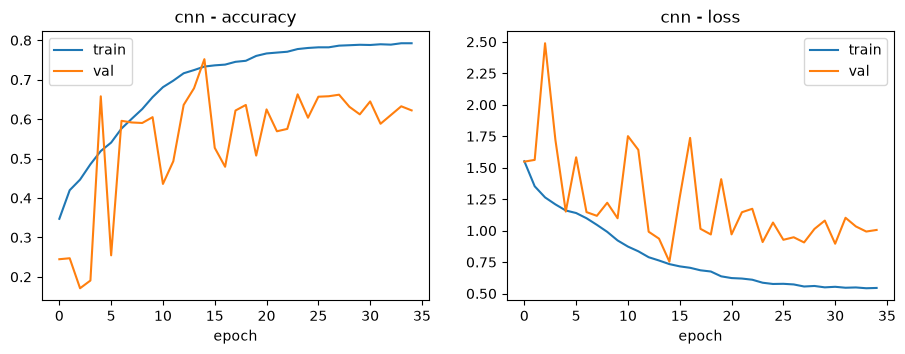

In [28]:
plot_curves(cnn_hist, "cnn")

In [29]:
cnn_true, cnn_pred = quick_eval(cnn, "cnn", test_ds)

cnn: test accuracy = 0.6387 | macro-F1 = 0.5778


## Deep Neural Network (DNN)

#### Build

In [30]:
def build_dnn(input_size=CFG.INPUT_SIZE, n_classes=N_CLASSES, lr=3e-4):
    # Batch normalisation after each dense layer, and a lower learning rate
    # than the CNN uses, stabilise training
    model = keras.Sequential([
        keras.Input((input_size, input_size, 3)),
        make_augment(),
        layers.Rescaling(1.0 / 255),
        layers.Flatten(),
        layers.Dense(512),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.5),
        layers.Dense(256),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.4),
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ], name="dnn_from_scratch")

    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", BalancedAccuracy(n_classes)])
    return model

dnn = build_dnn()
dnn.summary()

Model: "dnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augment (Sequential)            │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,460,550 (24.65 MB)

 Trainable params: 6,458,758 (24.64 MB)

 Non-trainable params: 1,792 (7.00 KB)

#### Train

In [31]:
set_seed()
dnn_hist = train_model(dnn, "dnn", train_ds, val_ds, class_weight=class_weight)

Epoch 1/40


/home/zechn/miniconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


345/345 - 34s - 98ms/step - accuracy: 0.3098 - balanced_accuracy: 0.3539 - loss: 1.6403 - val_accuracy: 0.1313 - val_balanced_accuracy: 0.3361 - val_loss: 1.7728 - learning_rate: 3.0000e-04
Epoch 2/40
345/345 - 22s - 64ms/step - accuracy: 0.3796 - balanced_accuracy: 0.4292 - loss: 1.4294 - val_accuracy: 0.0897 - val_balanced_accuracy: 0.3039 - val_loss: 1.8587 - learning_rate: 3.0000e-04
Epoch 3/40
345/345 - 24s - 68ms/step - accuracy: 0.4046 - balanced_accuracy: 0.4572 - loss: 1.3614 - val_accuracy: 0.2901 - val_balanced_accuracy: 0.4134 - val_loss: 1.5834 - learning_rate: 3.0000e-04
Epoch 4/40
345/345 - 22s - 65ms/step - accuracy: 0.4187 - balanced_accuracy: 0.4706 - loss: 1.3186 - val_accuracy: 0.3092 - val_balanced_accuracy: 0.4109 - val_loss: 1.5669 - learning_rate: 3.0000e-04
Epoch 5/40
345/345 - 22s - 65ms/step - accuracy: 0.4413 - balanced_accuracy: 0.4928 - loss: 1.2822 - val_accuracy: 0.2623 - val_balanced_accuracy: 0.3373 - val_loss: 1.6667 - learning_rate: 3.0000e-04
Epoch 

Plot validation curves

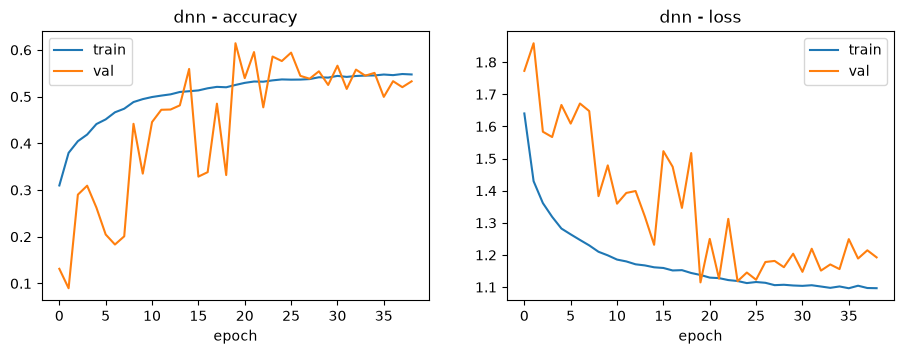

In [32]:
plot_curves(dnn_hist, "dnn")

In [42]:
dnn_true, dnn_pred = quick_eval(dnn, "dnn", test_ds)

dnn: test accuracy = 0.5465 | macro-F1 = 0.4456


## Hyperparameter Tuning (CNN & DNN)

#### Tune CNN

Search

In [33]:
def cnn_hypermodel_narrow(hp):
    lr    = hp.Choice("lr", [1e-3, 5e-4, 3e-4, 1e-4])
    f0    = hp.Choice("filters", [24, 32, 40])
    drop  = hp.Float("dropout", 0.2, 0.4, step=0.1)
    dense = hp.Choice("dense_units", [96, 128, 160])

    model = keras.Sequential([keras.Input((CFG.INPUT_SIZE, CFG.INPUT_SIZE, 3)),
                              make_augment(), layers.Rescaling(1.0 / 255)])
    for mult in (1, 2, 4):
        model.add(layers.Conv2D(f0 * mult, 3, padding="same"))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.Conv2D(f0 * mult, 3, padding="same"))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.MaxPooling2D())
        model.add(layers.Dropout(drop))
    model.add(layers.Flatten())
    model.add(layers.Dense(dense, activation="relu"))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(N_CLASSES, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", BalancedAccuracy(N_CLASSES)])
    return model

In [ ]:
cnn_tuner_narrow = kt.RandomSearch(cnn_hypermodel_narrow,
                                   objective=kt.Objective("val_balanced_accuracy", direction="max"),
                                   max_trials=10, executions_per_trial=2,
                                   directory=CFG.MODEL_DIR, project_name="cnn_tuning_narrow",
                                   seed=CFG.SEED, overwrite=False)
cnn_tuner_narrow.search(train_ds, validation_data=val_ds, epochs=CFG.TUNE_EPOCHS,
                        class_weight=class_weight,
                        callbacks=[keras.callbacks.EarlyStopping(monitor="val_balanced_accuracy", mode="max",
                                                                 patience=4, restore_best_weights=True)])

cnn_narrow_best_hp = cnn_tuner_narrow.get_best_hyperparameters(1)[0]
print("Narrowed CNN best hyperparameters:", cnn_narrow_best_hp.values)
print("Narrowed CNN best val_balanced_accuracy:",
      max(t.score for t in cnn_tuner_narrow.oracle.trials.values() if t.score is not None))

Trial 3 Complete [00h 23m 35s]
val_balanced_accuracy: 0.6687934696674347

Best val_balanced_accuracy So Far: 0.6687934696674347
Total elapsed time: 01h 13m 16s

Search: Running Trial #4

Value             |Best Value So Far |Hyperparameter
0.0001            |0.0005            |lr
24                |24                |filters
0.4               |0.4               |dropout
96                |128               |dense_units

Epoch 1/15


E0000 00:00:1789730695.259177   74973 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


345/345 ━━━━━━━━━━━━━━━━━━━━ 73s 168ms/step - accuracy: 0.3175 - balanced_accuracy: 0.3556 - loss: 1.5957 - val_accuracy: 0.0899 - val_balanced_accuracy: 0.2009 - val_loss: 3.2965
Epoch 2/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 55s 158ms/step - accuracy: 0.4365 - balanced_accuracy: 0.4955 - loss: 1.2764 - val_accuracy: 0.1768 - val_balanced_accuracy: 0.3959 - val_loss: 1.8488
Epoch 3/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 54s 157ms/step - accuracy: 0.4924 - balanced_accuracy: 0.5420 - loss: 1.1831 - val_accuracy: 0.3236 - val_balanced_accuracy: 0.4463 - val_loss: 1.4141
Epoch 4/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 82s 157ms/step - accuracy: 0.5280 - balanced_accuracy: 0.5698 - loss: 1.1220 - val_accuracy: 0.3482 - val_balanced_accuracy: 0.4255 - val_loss: 1.9400
Epoch 5/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 54s 156ms/step - accuracy: 0.5565 - balanced_accuracy: 0.5935 - loss: 1.0753 - val_accuracy: 0.2472 - val_balanced_accuracy: 0.4437 - val_loss: 2.0115
Epoch 6/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 54s 156ms/step -

E0000 00:00:1789731134.835742   74973 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


163/345 ━━━━━━━━━━━━━━━━━━━━ 10:28 3s/step - accuracy: 0.2527 - balanced_accuracy: 0.2828 - loss: 1.7679

KeyboardInterrupt: 

In [42]:
print(cnn_tuner_narrow.get_best_hyperparameters(1)[0].values)

{'lr': 0.0005, 'filters': 24, 'dropout': 0.4, 'dense_units': 128}


In [44]:
import gc
keras.backend.clear_session()
gc.collect()

0

In [34]:
cnn_tuner_narrow = kt.RandomSearch(cnn_hypermodel_narrow,
                                   objective=kt.Objective("val_balanced_accuracy", direction="max"),
                                   max_trials=10, executions_per_trial=2,
                                   directory=CFG.MODEL_DIR, project_name="cnn_tuning_narrow",
                                   seed=CFG.SEED, overwrite=False)
print(cnn_tuner_narrow.get_best_hyperparameters(1)[0].values)

Reloading Tuner from /mnt/c/dev/APU/ODL/models/cnn_tuning_narrow/tuner0.json
{'lr': 0.0005, 'filters': 24, 'dropout': 0.4, 'dense_units': 128}


Retrain Best Model

In [37]:
cnn_best_hp = cnn_tuner_narrow.get_best_hyperparameters(1)[0]
print("CNN best hyperparameters:", cnn_best_hp.values)

cnn_tuned = cnn_tuner_narrow.hypermodel.build(cnn_best_hp)

set_seed()
cnn_tuned_hist = train_model(cnn_tuned, "cnn_tuned", train_ds, val_ds, class_weight=class_weight)

CNN best hyperparameters: {'lr': 0.0005, 'filters': 24, 'dropout': 0.4, 'dense_units': 128}
Epoch 1/40


E0000 00:00:1789738864.626871  103557 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1_1/dropout_2_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


345/345 - 73s - 211ms/step - accuracy: 0.2640 - balanced_accuracy: 0.3341 - loss: 1.6018 - val_accuracy: 0.0916 - val_balanced_accuracy: 0.1908 - val_loss: 3.5440 - learning_rate: 5.0000e-04
Epoch 2/40
345/345 - 58s - 167ms/step - accuracy: 0.3847 - balanced_accuracy: 0.4322 - loss: 1.3500 - val_accuracy: 0.1105 - val_balanced_accuracy: 0.3801 - val_loss: 1.6247 - learning_rate: 5.0000e-04
Epoch 3/40
345/345 - 54s - 156ms/step - accuracy: 0.4313 - balanced_accuracy: 0.4878 - loss: 1.2418 - val_accuracy: 0.1979 - val_balanced_accuracy: 0.3634 - val_loss: 1.4938 - learning_rate: 5.0000e-04
Epoch 4/40
345/345 - 54s - 155ms/step - accuracy: 0.4711 - balanced_accuracy: 0.5070 - loss: 1.1952 - val_accuracy: 0.0703 - val_balanced_accuracy: 0.2711 - val_loss: 2.0194 - learning_rate: 5.0000e-04
Epoch 5/40
345/345 - 55s - 158ms/step - accuracy: 0.5156 - balanced_accuracy: 0.5407 - loss: 1.1314 - val_accuracy: 0.3079 - val_balanced_accuracy: 0.4068 - val_loss: 1.5484 - learning_rate: 5.0000e-04
E

Plot tuned CNN validation curves

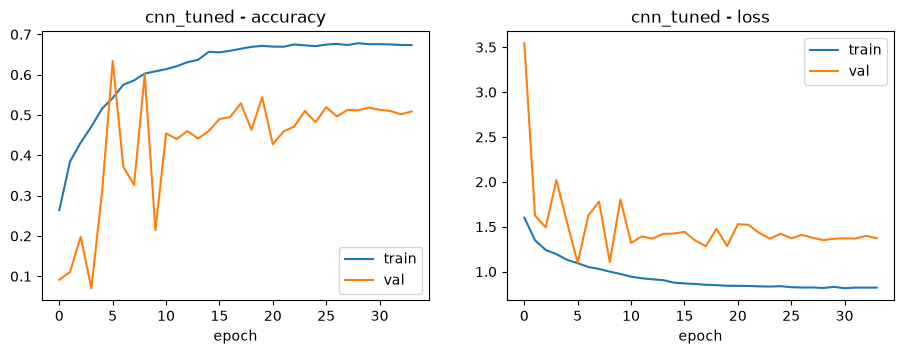

In [38]:
plot_curves(cnn_tuned_hist, "cnn_tuned")

In [39]:
cnn_tuned_true, cnn_tuned_pred = quick_eval(cnn_tuned, "cnn_tuned", test_ds)

cnn_tuned: test accuracy = 0.5105 | macro-F1 = 0.5041


#### Tune DNN

##### Search

In [35]:
def dnn_hypermodel(hp):
    lr    = hp.Choice("lr", [1e-3, 3e-4, 1e-4])
    u1    = hp.Choice("units1", [256, 512, 768])
    u2    = hp.Choice("units2", [128, 256, 384])
    drop  = hp.Float("dropout", 0.2, 0.5, step=0.1)

    # batch normalisation stabilises training here too, same reasoning as build_dnn
    model = keras.Sequential([
        keras.Input((CFG.INPUT_SIZE, CFG.INPUT_SIZE, 3)),
        make_augment(), layers.Rescaling(1.0 / 255), layers.Flatten(),
        layers.Dense(u1), layers.BatchNormalization(), layers.Activation("relu"), layers.Dropout(drop),
        layers.Dense(u2), layers.BatchNormalization(), layers.Activation("relu"), layers.Dropout(drop),
        layers.Dense(N_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy", BalancedAccuracy(N_CLASSES)])
    return model

In [36]:
dnn_tuner = kt.RandomSearch(dnn_hypermodel, objective=kt.Objective("val_balanced_accuracy", direction="max"),
                            max_trials=CFG.TUNE_TRIALS, executions_per_trial=2,
                            directory=CFG.MODEL_DIR, project_name="dnn_tuning",
                            seed=CFG.SEED, overwrite=True)
dnn_tuner.search(train_ds, validation_data=val_ds, epochs=CFG.TUNE_EPOCHS,
                 class_weight=class_weight,
                 callbacks=[keras.callbacks.EarlyStopping(monitor="val_balanced_accuracy", mode="max",
                                                          patience=4, restore_best_weights=True)])

Trial 4 Complete [00h 09m 24s]
val_balanced_accuracy: 0.4560891091823578

Best val_balanced_accuracy So Far: 0.4560891091823578
Total elapsed time: 00h 27m 04s

Search: Running Trial #5

Value             |Best Value So Far |Hyperparameter
0.0003            |0.0001            |lr
256               |256               |units1
128               |384               |units2
0.3               |0.2               |dropout

Epoch 1/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 28s 59ms/step - accuracy: 0.3567 - balanced_accuracy: 0.3974 - loss: 1.5402 - val_accuracy: 0.1165 - val_balanced_accuracy: 0.2832 - val_loss: 1.9236
Epoch 2/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.4134 - balanced_accuracy: 0.4595 - loss: 1.3705 - val_accuracy: 0.4765 - val_balanced_accuracy: 0.4122 - val_loss: 1.2871
Epoch 3/15
345/345 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.4314 - balanced_accuracy: 0.4816 - loss: 1.3220 - val_accuracy: 0.2047 - val_balanced_accuracy: 0.3548 - val_loss: 1.5784
Epoch 4/15
3

KeyboardInterrupt: 

##### Retrain Best Model

In [47]:
dnn_best_hp = dnn_tuner.get_best_hyperparameters(1)[0]
print("DNN best hyperparameters:", dnn_best_hp.values)

dnn_tuned = dnn_tuner.hypermodel.build(dnn_best_hp)

DNN best hyperparameters: {'lr': 0.0001, 'units1': 256, 'units2': 384, 'dropout': 0.2}


In [48]:
set_seed()
dnn_tuned_hist = train_model(dnn_tuned, "dnn_tuned", train_ds, val_ds, class_weight=class_weight)

/home/zechn/miniconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/40
345/345 - 36s - 105ms/step - accuracy: 0.3704 - balanced_accuracy: 0.4125 - loss: 1.5166 - val_accuracy: 0.1436 - val_balanced_accuracy: 0.3339 - val_loss: 2.1864 - learning_rate: 1.0000e-04
Epoch 2/40


W0000 00:00:1789741911.022271  130677 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 8390144 bytes after encountering the first element of size 8390144 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


345/345 - 77s - 222ms/step - accuracy: 0.4205 - balanced_accuracy: 0.4649 - loss: 1.3778 - val_accuracy: 0.1265 - val_balanced_accuracy: 0.3097 - val_loss: 2.2402 - learning_rate: 1.0000e-04
Epoch 3/40
345/345 - 26s - 75ms/step - accuracy: 0.4477 - balanced_accuracy: 0.4900 - loss: 1.3096 - val_accuracy: 0.5206 - val_balanced_accuracy: 0.4077 - val_loss: 1.1965 - learning_rate: 1.0000e-04
Epoch 4/40
345/345 - 21s - 61ms/step - accuracy: 0.4604 - balanced_accuracy: 0.5033 - loss: 1.2738 - val_accuracy: 0.1567 - val_balanced_accuracy: 0.3523 - val_loss: 2.2744 - learning_rate: 1.0000e-04
Epoch 5/40
345/345 - 20s - 59ms/step - accuracy: 0.4761 - balanced_accuracy: 0.5184 - loss: 1.2393 - val_accuracy: 0.1743 - val_balanced_accuracy: 0.3345 - val_loss: 1.8509 - learning_rate: 1.0000e-04
Epoch 6/40
345/345 - 29s - 84ms/step - accuracy: 0.4835 - balanced_accuracy: 0.5242 - loss: 1.2204 - val_accuracy: 0.1727 - val_balanced_accuracy: 0.3151 - val_loss: 2.1023 - learning_rate: 1.0000e-04
Epoch

##### Evaluate

Plot tuned DNN validation curves

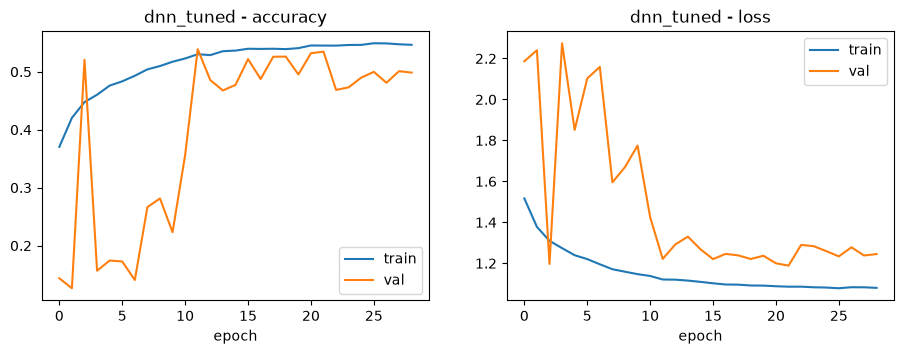

In [49]:
plot_curves(dnn_tuned_hist, "dnn_tuned")

In [50]:
dnn_tuned_true, dnn_tuned_pred = quick_eval(dnn_tuned, "dnn_tuned", test_ds)

dnn_tuned: test accuracy = 0.5128 | macro-F1 = 0.4232


#### Plot CNN & DNN trial results

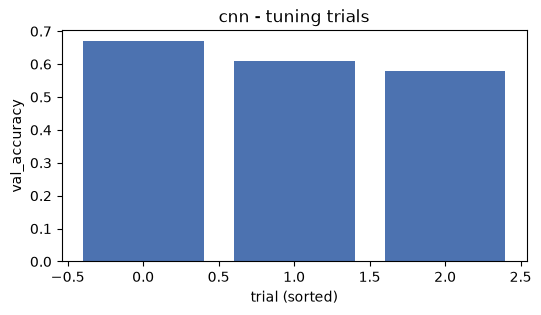

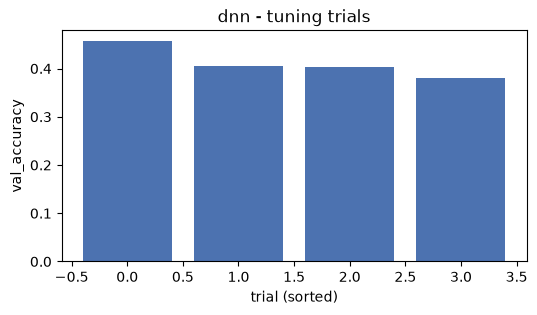

In [40]:
def plot_tuner_trials(tuner, tag):
    scores = sorted((t.score for t in tuner.oracle.trials.values() if t.score is not None),
                    reverse=True)
    plt.figure(figsize=(6, 3))
    plt.bar(range(len(scores)), scores, color="#4C72B0")
    plt.xlabel("trial (sorted)"); plt.ylabel("val_accuracy")
    plt.title(f"{tag} - tuning trials")
    plt.savefig(f"{CFG.FIG_DIR}/{tag}_tuning_trials.png"); plt.show()

plot_tuner_trials(cnn_tuner_narrow, "cnn")
plot_tuner_trials(dnn_tuner, "dnn")

#### Tuning Summary

In [51]:
tuning_summary = pd.DataFrame({
    "model": ["CNN - baseline", "CNN - tuned", "DNN - baseline", "DNN - tuned"],
    "test_acc": [
        (cnn_true == cnn_pred).mean(),
        (cnn_tuned_true == cnn_tuned_pred).mean(),
        (dnn_true == dnn_pred).mean(),
        (dnn_tuned_true == dnn_tuned_pred).mean(),
    ],
    "macro_f1": [
        f1_score(cnn_true, cnn_pred, average="macro"),
        f1_score(cnn_tuned_true, cnn_tuned_pred, average="macro"),
        f1_score(dnn_true, dnn_pred, average="macro"),
        f1_score(dnn_tuned_true, dnn_tuned_pred, average="macro"),
    ],
})
tuning_summary[["test_acc", "macro_f1"]] = tuning_summary[["test_acc", "macro_f1"]].round(4)
print(tuning_summary.to_string(index=False))
tuning_summary.to_csv(f"{CFG.FIG_DIR}/tuning_before_after.csv", index=False)

         model  test_acc  macro_f1
CNN - baseline    0.6387    0.5778
   CNN - tuned    0.5105    0.5041
DNN - baseline    0.5465    0.4456
   DNN - tuned    0.5128    0.4232


## Evaluation

#### Full report generation

===== CNN (baseline) =====
              precision    recall  f1-score   support

         CCA      0.959     0.565     0.711     13178
  Hard coral      0.677     0.617     0.645      1809
        Sand      0.547     0.882     0.675      1591
        Turf      0.234     0.915     0.372       922
  Macroalgae      0.163     0.759     0.268       406
       Other      0.678     0.963     0.796       999

    accuracy                          0.639     18905
   macro avg      0.543     0.783     0.578     18905
weighted avg      0.830     0.639     0.680     18905



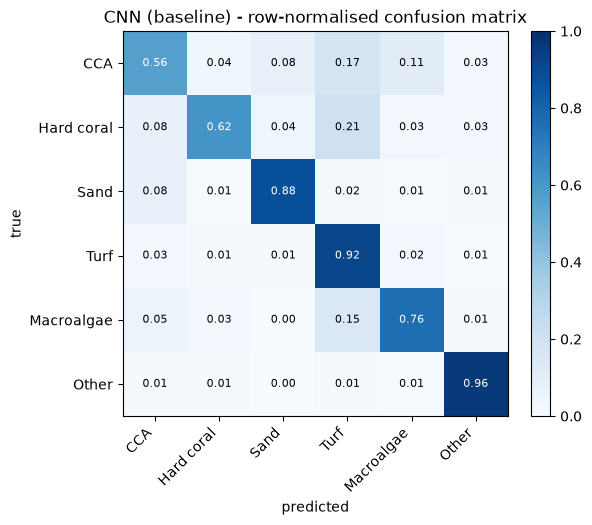

===== DNN (baseline) =====
              precision    recall  f1-score   support

         CCA      0.923     0.504     0.652     13178
  Hard coral      0.337     0.448     0.384      1809
        Sand      0.432     0.727     0.542      1591
        Turf      0.198     0.679     0.307       922
  Macroalgae      0.130     0.431     0.200       406
       Other      0.431     0.920     0.587       999

    accuracy                          0.547     18905
   macro avg      0.409     0.618     0.446     18905
weighted avg      0.748     0.547     0.587     18905



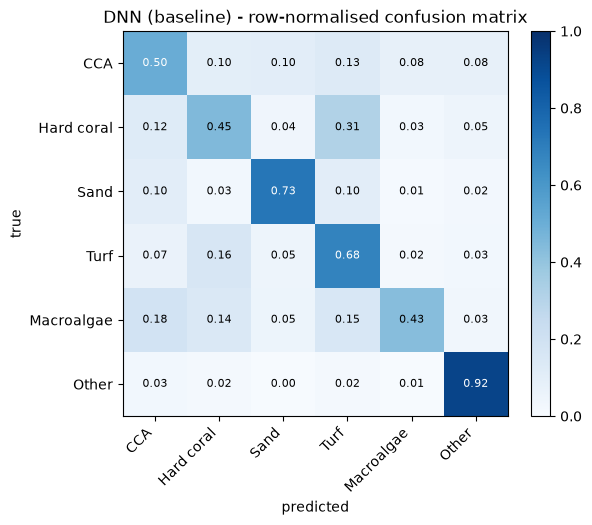

===== CNN (tuned) =====
              precision    recall  f1-score   support

         CCA      0.945     0.445     0.605     13178
  Hard coral      0.867     0.263     0.403      1809
        Sand      0.563     0.805     0.663      1591
        Turf      0.119     0.969     0.212       922
  Macroalgae      0.224     0.665     0.335       406
       Other      0.750     0.875     0.808       999

    accuracy                          0.510     18905
   macro avg      0.578     0.670     0.504     18905
weighted avg      0.839     0.510     0.576     18905



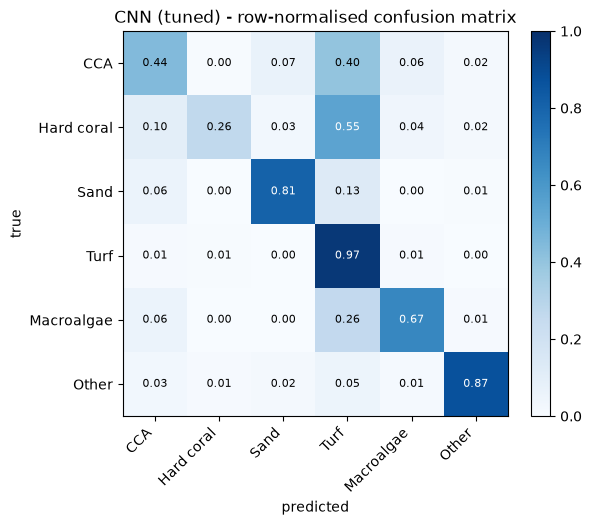

===== DNN (tuned) =====
              precision    recall  f1-score   support

         CCA      0.912     0.458     0.610     13178
  Hard coral      0.381     0.386     0.383      1809
        Sand      0.434     0.748     0.550      1591
        Turf      0.200     0.707     0.312       922
  Macroalgae      0.096     0.451     0.159       406
       Other      0.365     0.936     0.525       999

    accuracy                          0.513     18905
   macro avg      0.398     0.614     0.423     18905
weighted avg      0.740     0.513     0.554     18905



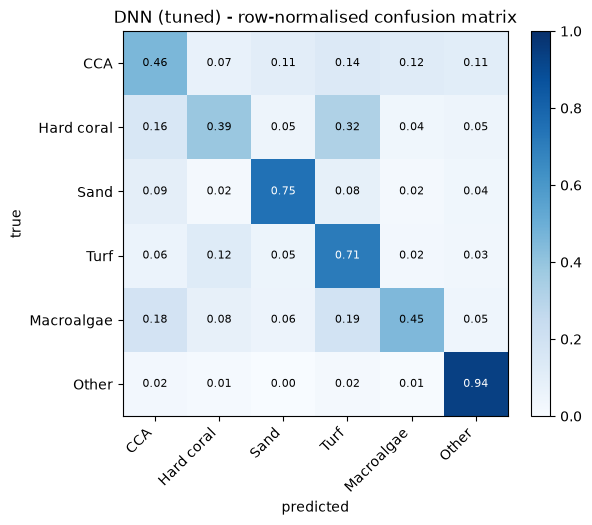

In [52]:
def full_report(y_true, y_pred, tag):
    print(f"===== {tag} =====")
    print(classification_report(y_true, y_pred, target_names=CFG.CLASSES, digits=3))

    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CFG.CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CFG.CLASSES)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{tag} - row-normalised confusion matrix")
    fig.colorbar(im, fraction=0.046)
    plt.savefig(f"{CFG.FIG_DIR}/{tag.lower()}_confusion.png"); plt.show()

full_report(cnn_true, cnn_pred, "CNN (baseline)")
full_report(dnn_true, dnn_pred, "DNN (baseline)")
full_report(cnn_tuned_true, cnn_tuned_pred, "CNN (tuned)")
full_report(dnn_tuned_true, dnn_tuned_pred, "DNN (tuned)")

## Comparison Summary

In [46]:
summary = pd.DataFrame({
    "model":    ["CNN (baseline)", "DNN (baseline)"],
    "params":   [cnn.count_params(), dnn.count_params()],
    "test_acc": [(cnn_true == cnn_pred).mean(),
                 (dnn_true == dnn_pred).mean()],
    "macro_f1": [f1_score(cnn_true, cnn_pred, average="macro"),
                 f1_score(dnn_true, dnn_pred, average="macro")],
})
summary["test_acc"] = summary.test_acc.round(4)
summary["macro_f1"] = summary.macro_f1.round(4)
print(summary.to_string(index=False))
summary.to_csv(f"{CFG.FIG_DIR}/model_comparison.csv", index=False)

         model  params  test_acc  macro_f1
CNN (baseline) 1338278    0.6387    0.5778
DNN (baseline) 6460550    0.5465    0.4456
